# Consultas

Grafo de 6 vertices (6, 11) de `03_ContraejemploWurth`, el candidato descartado (mejor con un puente) y sus F-tuplas.

In [2]:
import os
RAIZ = os.path.abspath("..")
os.chdir(RAIZ)
load("DataTypes/GrafoKTerminales.sage")
load("Scripts/FiltroLexicografico.sage")
load("Scripts/ContraejemploWurth.sage")

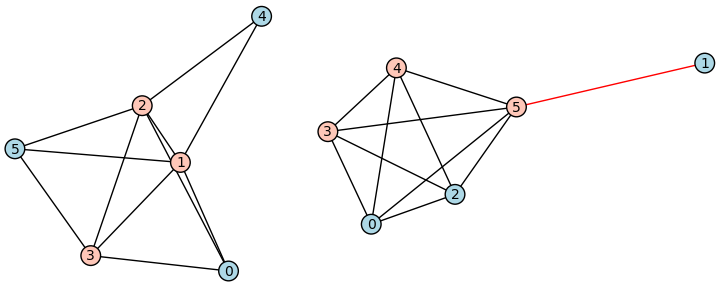

In [3]:
c = certificar(6, 11, verbose=False)
G, H = c["G"], c["H"]   # G: ganador sin puentes, H: candidato descartado (con puente)
graphics_array([G.dibujar(), H.dibujar()]).show(figsize=[8, 3])

In [4]:
print("F(G) =", list(G.F_tupla()))
print("F(H) =", list(H.F_tupla()))

F(G) = [0, 0, 0, 0, 2, 13, 47, 84, 0, 0, 0]
F(H) = [0, 0, 0, 0, 2, 12, 39, 65, 0, 0, 0]


## Primera coordenada en que discrepan (fuerza bruta)

In [5]:
FG, FH = list(G.F_tupla()), list(H.F_tupla())
for i in range(min(len(FG), len(FH))):
    if FG[i] != FH[i]:
        print(f"Primera discrepancia en la posicion {i + 1}: F_{i + 1}(G) = {FG[i]}, F_{i + 1}(H) = {FH[i]}")
        break
else:
    print("No discrepan")

Primera discrepancia en la posicion 6: F_6(G) = 13, F_6(H) = 12


In [6]:
def formas(X, i):
    """Conjuntos de i aristas cuya eliminacion deja k componentes con los terminales separados."""
    g, ts = X.grafo(), X.terminales()
    aristas = list(g.edges(labels=False, sort=True))
    res = []
    for borradas in Combinations(aristas, i):
        h = Graph(g, immutable=False)
        h.delete_edges(borradas)
        comps = h.connected_components()
        if len(comps) == X.k() and len({next(j for j, C in enumerate(comps) if t in C) for t in ts}) == X.k():
            res.append(borradas)
    return res

j = next(i + 1 for i in range(len(FG)) if FG[i] != FH[i])
for nombre, X in [("G", G), ("H", H)]:
    fs = formas(X, j)
    print(f"{nombre}: {len(fs)} formas de borrar {j} aristas")
    for b in fs:
        print("  ", b)

G: 13 formas de borrar 6 aristas
   [(0, 1), (0, 2), (0, 3), (1, 2), (1, 4), (2, 4)]
   [(0, 1), (0, 2), (0, 3), (1, 3), (1, 4), (2, 4)]
   [(0, 1), (0, 2), (0, 3), (1, 4), (1, 5), (2, 4)]
   [(0, 1), (0, 2), (0, 3), (1, 4), (2, 3), (2, 4)]
   [(0, 1), (0, 2), (0, 3), (1, 4), (2, 4), (2, 5)]
   [(0, 1), (0, 2), (0, 3), (1, 4), (2, 4), (3, 5)]
   [(0, 1), (0, 2), (0, 3), (1, 5), (2, 5), (3, 5)]
   [(0, 1), (1, 4), (1, 5), (2, 4), (2, 5), (3, 5)]
   [(0, 2), (1, 4), (1, 5), (2, 4), (2, 5), (3, 5)]
   [(0, 3), (1, 4), (1, 5), (2, 4), (2, 5), (3, 5)]
   [(1, 2), (1, 4), (1, 5), (2, 4), (2, 5), (3, 5)]
   [(1, 3), (1, 4), (1, 5), (2, 4), (2, 5), (3, 5)]
   [(1, 4), (1, 5), (2, 3), (2, 4), (2, 5), (3, 5)]
H: 12 formas de borrar 6 aristas
   [(0, 2), (0, 3), (0, 4), (0, 5), (1, 5), (2, 3)]
   [(0, 2), (0, 3), (0, 4), (0, 5), (1, 5), (2, 4)]
   [(0, 2), (0, 3), (0, 4), (0, 5), (1, 5), (2, 5)]
   [(0, 2), (0, 3), (0, 4), (0, 5), (1, 5), (3, 4)]
   [(0, 2), (0, 3), (0, 4), (0, 5), (1, 5), (3, 5)

## Maximizantes lexicograficos en (n, m) = (6, 11), k = 3

Se recorren todas las clases de isomorfismo de grafos conexos con 6 vertices y 11 aristas (nauty) y, en cada una, las  elecciones de 3 terminales bajo Aut(G). Se compara la F-tupla (F_1, ..., F_11) lexicograficamente y se conservan los grafos 3-terminales que la maximizan. Se muestran sus F-tuplas, la segunda mejor tupla y su dibujo.

Candidatos comparados: 69
F-tupla maxima: [0, 0, 0, 0, 2, 13, 47, 84, 0, 0, 0]
Segunda mejor:  [0, 0, 0, 0, 2, 12, 39, 65, 0, 0, 0]  (se decide en F_6)
Clases ganadoras no isomorfas: 1
[(0, 3), (0, 4), (0, 5), (1, 3), (1, 4), (1, 5), (2, 4), (2, 5), (3, 4), (3, 5), (4, 5)] terminales [0, 1, 2] puentes 0


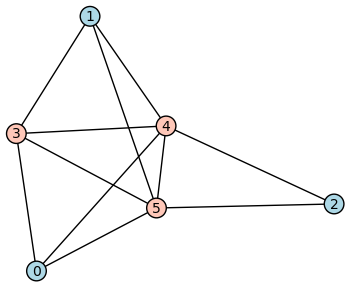

In [7]:
r = ganadores(6, 11, 3)
print(f"Candidatos comparados: {r.candidatos}")
print(f"F-tupla maxima: {list(r.tupla_maxima)}")
print(f"Segunda mejor:  {list(r.segunda_tupla)}  (se decide en F_{r.indice_discriminante})")
print(f"Clases ganadoras no isomorfas: {len(r.ganadores)}")
for W in r.ganadores:
    print(sorted(W.grafo().edges(labels=False)), "terminales", list(W.terminales()), "puentes", W.numero_puentes())
graphics_array([W.dibujar() for W in r.ganadores]).show(figsize=[4 * len(r.ganadores), 3])